## Import libraries & load dataset

Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load IMDB Dataset

In [2]:
df = pd.read_csv("data/IMDB-Dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Clean Dataset

Remove duplicates

In [3]:
print("Original dataset:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset after removing duplicates:", df.shape)

Original dataset: (50000, 2)
Duplicate rows: 418
Dataset after removing duplicates: (49582, 2)


Clean HTML Tags and Formatting

In [4]:
import re
import html

def clean_text(text):
    # Convert HTML entities to regular characters
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert text to lowercase
    text = text.lower()

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["cleaned_review"] = df["review"].apply(clean_text)

Compare the original and cleaned reviews

In [5]:
print("ORIGINAL REVIEW:")
print(df["review"].iloc[0][:500])

print("\nCLEANED REVIEW:")
print(df["cleaned_review"].iloc[0][:500])

ORIGINAL REVIEW:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

CLEANED REVIEW:
one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me. the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word. it

Convert sentiment labels into numbers

In [6]:
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df[["sentiment", "label"]].head())

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1


In [7]:
print("Final dataset shape:", df.shape)

print("\nSentiment distribution:")
print(df["label"].value_counts())

print("\nMissing labels:")
print(df["label"].isnull().sum())

Final dataset shape: (49582, 4)

Sentiment distribution:
label
1    24884
0    24698
Name: count, dtype: int64

Missing labels:
0


Check for duplicate reviews

In [8]:
# Count duplicate cleaned reviews
duplicate_count = df.duplicated(subset=["cleaned_review"]).sum()

print("Duplicate cleaned reviews:", duplicate_count)

Duplicate cleaned reviews: 4


Check for conflicting sentiment labels

In [9]:
# Count unique sentiment labels for each review
label_counts = df.groupby("cleaned_review")["label"].nunique()

# Find reviews that have more than one sentiment label
conflicting_reviews = label_counts[label_counts > 1]

print("Reviews with conflicting labels:", len(conflicting_reviews))

Reviews with conflicting labels: 0


In [10]:
df = df.drop_duplicates(subset=["cleaned_review"]).reset_index(drop=True)

print("Final dataset size:", len(df))
print("Remaining duplicate reviews:", df.duplicated(subset=["cleaned_review"]).sum())

Final dataset size: 49578
Remaining duplicate reviews: 0


## Preprocessing

Split the dataset for training, testing & validation

In [11]:
from sklearn.model_selection import train_test_split

X = df["cleaned_review"]
y = df["label"]

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 34704
Validation samples: 7437
Testing samples: 7437


Convert the text into TF-IDF features

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (34704, 5000)
Validation TF-IDF shape: (7437, 5000)
Testing TF-IDF shape: (7437, 5000)


## Logistic Regression Model

In [13]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [14]:
from sklearn.metrics import accuracy_score, classification_report

# Generate predictions
y_val_pred_lr = lr_model.predict(X_val_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_val_pred_lr)

print(f"Validation Accuracy: {accuracy:.4f}")

# Precision, Recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_lr,
    target_names=["Negative", "Positive"]
))

Validation Accuracy: 0.8915

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.87      0.89      3704
    Positive       0.88      0.91      0.89      3733

    accuracy                           0.89      7437
   macro avg       0.89      0.89      0.89      7437
weighted avg       0.89      0.89      0.89      7437



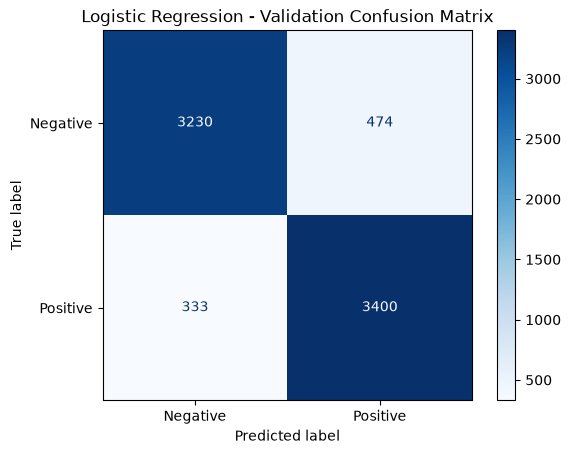

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    lr_model,
    X_val_tfidf,
    y_val,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

Examine most influential words

In [16]:
import numpy as np

# Get feature names and model coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = lr_model.coef_[0]

# Find the 10 most influential positive and negative words
top_positive = np.argsort(coefficients)[-10:][::-1]
top_negative = np.argsort(coefficients)[:10]

print("Top 10 Positive Words:")
for i in top_positive:
    print(f"{feature_names[i]}: {coefficients[i]:.3f}")

print("\nTop 10 Negative Words:")
for i in top_negative:
    print(f"{feature_names[i]}: {coefficients[i]:.3f}")

Top 10 Positive Words:
great: 7.799
excellent: 6.972
perfect: 5.284
best: 5.186
amazing: 5.081
wonderful: 4.620
favorite: 4.130
today: 4.087
enjoyed: 4.067
loved: 4.046

Top 10 Negative Words:
worst: -10.282
bad: -7.820
awful: -7.452
waste: -7.071
boring: -7.003
poor: -5.963
terrible: -5.809
worse: -5.176
horrible: -5.118
nothing: -5.051


## Neural Network Model

In [17]:
import torch

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cu130


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cpu")

print("Training device:", device)

Training device: cpu


Feedforward Neural Network

In [19]:
class SentimentNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

Initialize Model

In [20]:
input_size = X_train_tfidf.shape[1]


Define Loss Function & Optimizer

In [21]:
import copy

# Set random seed for reproducibility
torch.manual_seed(42)

# Create a new neural network
nn_model = SentimentNN(input_size).to(device)

# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Reset optimizer
optimizer = optim.Adam(
    nn_model.parameters(),
    lr=0.001
)

PyTorch Dataset

In [22]:
from torch.utils.data import Dataset, DataLoader
import numpy as np

class TfidfDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.tocsr()
        self.y = np.asarray(y, dtype=np.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        features = self.X[idx].toarray().flatten()
        label = self.y[idx]

        return (
            torch.tensor(features, dtype=torch.float32),
            torch.tensor(label, dtype=torch.float32)
        )

Create DataLoaders

In [23]:
train_dataset = TfidfDataset(X_train_tfidf, y_train)
val_dataset = TfidfDataset(X_val_tfidf, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

Training

In [24]:
num_epochs = 10

best_val_loss = float("inf")
best_model_weights = None
best_epoch = 0

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    nn_model.train()
    running_loss = 0

    for features, labels in train_loader:
        features = features.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        outputs = nn_model(features)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * features.size(0)

    avg_train_loss = running_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # Validation
    nn_model.eval()
    running_val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for features, labels in val_loader:
            features = features.to(device)
            labels = labels.to(device).unsqueeze(1)

            outputs = nn_model(features)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * features.size(0)

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = running_val_loss / len(val_dataset)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_weights = copy.deepcopy(nn_model.state_dict())
        best_epoch = epoch + 1
    
    val_accuracy = correct / total

    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

nn_model.load_state_dict(best_model_weights)
nn_model.eval()

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

/home/mhowa/projects/ds680_nlp_hw/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12070). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1/10 | Train Loss: 0.3383 | Val Loss: 0.2613 | Val Accuracy: 0.8931
Epoch 2/10 | Train Loss: 0.2215 | Val Loss: 0.2736 | Val Accuracy: 0.8897
Epoch 3/10 | Train Loss: 0.2054 | Val Loss: 0.2830 | Val Accuracy: 0.8857
Epoch 4/10 | Train Loss: 0.1947 | Val Loss: 0.2900 | Val Accuracy: 0.8836
Epoch 5/10 | Train Loss: 0.1869 | Val Loss: 0.2998 | Val Accuracy: 0.8826
Epoch 6/10 | Train Loss: 0.1755 | Val Loss: 0.3061 | Val Accuracy: 0.8803
Epoch 7/10 | Train Loss: 0.1534 | Val Loss: 0.3237 | Val Accuracy: 0.8780
Epoch 8/10 | Train Loss: 0.1225 | Val Loss: 0.3718 | Val Accuracy: 0.8793
Epoch 9/10 | Train Loss: 0.0866 | Val Loss: 0.4265 | Val Accuracy: 0.8771
Epoch 10/10 | Train Loss: 0.0543 | Val Loss: 0.5207 | Val Accuracy: 0.8739
Best epoch: 1
Best validation loss: 0.2613


Training Results

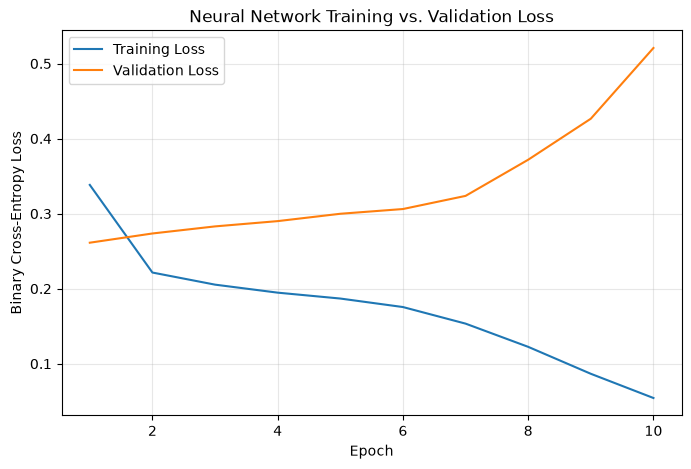

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, num_epochs + 1), train_losses, label="Training Loss")
plt.plot(range(1, num_epochs + 1), val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training vs. Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Model Evaluation

In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Ensure we're using the best model
nn_model.eval()

nn_val_predictions = []

with torch.no_grad():
    for features, labels in val_loader:
        features = features.to(device)

        outputs = nn_model(features)

        # Convert output scores into probabilities
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities into binary predictions
        predictions = (probabilities >= 0.5).int()

        nn_val_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

# Calculate accuracy
nn_val_accuracy = accuracy_score(
    y_val,
    nn_val_predictions
)

print(f"Neural Network Validation Accuracy: {nn_val_accuracy:.4f}")

print("\nNeural Network Classification Report:")
print(
    classification_report(
        y_val,
        nn_val_predictions,
        target_names=["Negative", "Positive"]
    )
)

Neural Network Validation Accuracy: 0.8931

Neural Network Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.88      0.89      3704
    Positive       0.88      0.91      0.90      3733

    accuracy                           0.89      7437
   macro avg       0.89      0.89      0.89      7437
weighted avg       0.89      0.89      0.89      7437



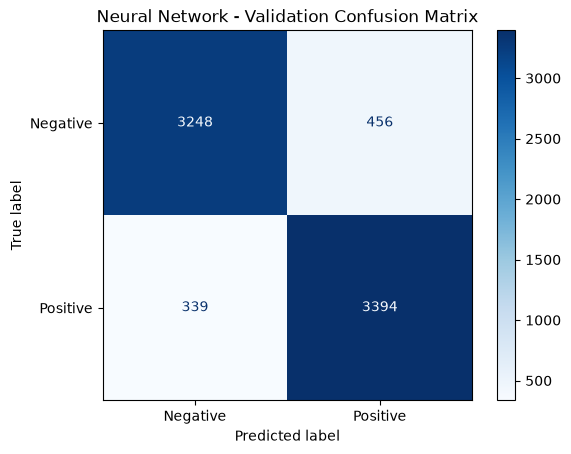

In [27]:
cm_nn = confusion_matrix(y_val, nn_val_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")

plt.title("Neural Network - Validation Confusion Matrix")
plt.show()

Final Model Comparison

In [28]:
# Logistic Regression: Test Predictions
y_test_pred_lr = lr_model.predict(X_test_tfidf)

print("LOGISTIC REGRESSION - TEST RESULTS")

print(
    "Test Accuracy:",
    round(accuracy_score(y_test, y_test_pred_lr), 4)
)

print(
    classification_report(
        y_test,
        y_test_pred_lr,
        target_names=["Negative", "Positive"]
    )
)

LOGISTIC REGRESSION - TEST RESULTS
Test Accuracy: 0.8919
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      3705
    Positive       0.88      0.90      0.89      3732

    accuracy                           0.89      7437
   macro avg       0.89      0.89      0.89      7437
weighted avg       0.89      0.89      0.89      7437



In [29]:
test_dataset = TfidfDataset(X_test_tfidf, y_test)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [30]:
nn_model.eval()

nn_test_predictions = []

with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)

        outputs = nn_model(features)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        nn_test_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

print("NEURAL NETWORK - TEST RESULTS")

print(
    "Test Accuracy:",
    round(accuracy_score(y_test, nn_test_predictions), 4)
)

print(
    classification_report(
        y_test,
        nn_test_predictions,
        target_names=["Negative", "Positive"]
    )
)

NEURAL NETWORK - TEST RESULTS
Test Accuracy: 0.8936
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.89      3705
    Positive       0.89      0.90      0.89      3732

    accuracy                           0.89      7437
   macro avg       0.89      0.89      0.89      7437
weighted avg       0.89      0.89      0.89      7437



In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Neural Network"],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred_lr),
        accuracy_score(y_test, nn_test_predictions)
    ],
    "Precision": [
        precision_score(y_test, y_test_pred_lr, average="weighted"),
        precision_score(y_test, nn_test_predictions, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, y_test_pred_lr, average="weighted"),
        recall_score(y_test, nn_test_predictions, average="weighted")
    ],
    "F1-Score": [
        f1_score(y_test, y_test_pred_lr, average="weighted"),
        f1_score(y_test, nn_test_predictions, average="weighted")
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8919,0.8921,0.8919,0.8919
1,Neural Network,0.8936,0.8937,0.8936,0.8936


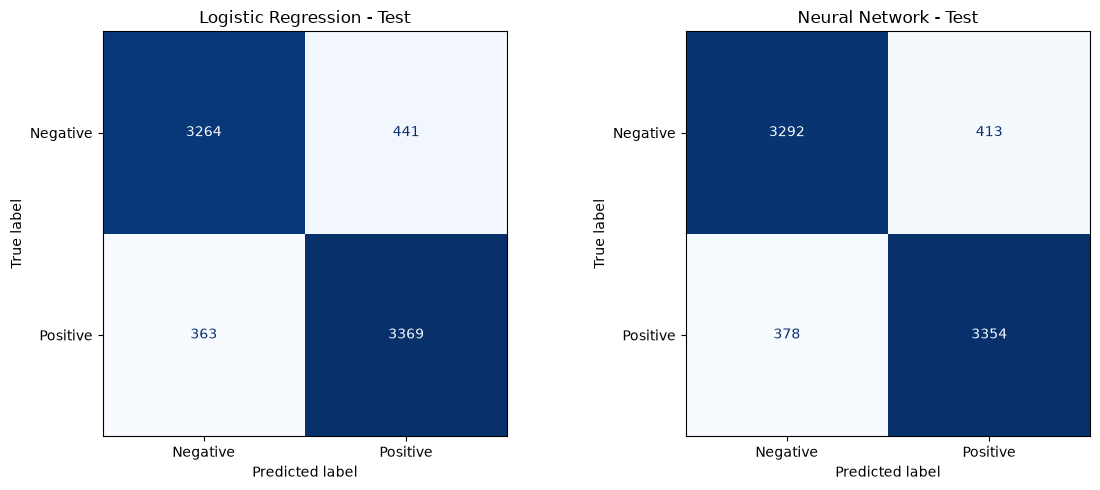

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_lr,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Logistic Regression - Test")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nn_test_predictions,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Neural Network - Test")

plt.tight_layout()
plt.show()